# 03 — Estudo de pré-processamento

**Objetivo:** testar **todas as combinações** de técnicas de pré-processamento (5 etapas, 144 pipelines) com a regressão logística, nos mesmos folds temporais do notebook 02, e medir o impacto de cada decisão e as interações entre elas.

> Só o treino (meses 0–5) é usado. O código compartilhado (limpeza, folds, métricas) vem de `src/`.

In [4]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/fraude-abertura-conta")
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAIZ = Path(os.getenv("FRAUDE_RAIZ", RAIZ))
DATA_DIR = RAIZ / "data"

sys.path.insert(0, str(RAIZ))  # permite "from src... import ..."
from src.preprocessamento import (ALVO, BINARIAS, CATEGORICAS, CAUDA_LONGA, DESCARTAR,
                                  NUMERICAS, VELOCIDADES, limpar)
from src.validacao import validar

treino = pd.read_parquet(DATA_DIR / "train.parquet")
assert treino["month"].between(0, 5).all()

# As listas do módulo cobrem exatamente as colunas da base?
grupos = NUMERICAS + CAUDA_LONGA + BINARIAS + CATEGORICAS + DESCARTAR + [ALVO]
assert sorted(grupos) == sorted(treino.columns), set(grupos) ^ set(treino.columns)
print(f"{len(treino):,} linhas | todas as {len(grupos)} colunas classificadas")

# O módulo reproduz o baseline ingênuo do notebook 02 (recall médio 0,213)?
validar(lambda tr, va: va["credit_risk_score"].to_numpy(), treino).round(3)

794,989 linhas | todas as 32 colunas classificadas


,recall@5%FPR,PR-AUC,ROC AUC
fold,,,
0–2 → 3,0.228,0.027,0.706
0–3 → 4,0.218,0.032,0.688
0–4 → 5,0.193,0.031,0.659
média,0.213,0.030,0.685
desvio padrão,0.018,0.003,0.024


## 1. As combinações

| Etapa | Opções |
|---|---|
| Ausentes | mediana **com** indicador de ausência · mediana **sem** indicador |
| Encoding | one-hot (categorias raras agrupadas) · target encoding |
| Escala | Standard · Robust · MinMax · nenhuma |
| Balanceamento | nenhum · `class_weight="balanced"` · undersampling (1 fraude : 10 legítimos, só no treino) |
| Seleção | nenhuma · sem as velocidades (drift, EDA seção 8) · SelectKBest (20 melhores pelo teste F) |

Fixos em todas: limpeza sem estado, `log1p` nas variáveis de cauda longa e regressão logística padrão (`max_iter=1000`). A configuração **mediana + indicador · one-hot · Standard · nenhum · nenhuma** é exatamente o pipeline do notebook 02 — serve de âncora.

In [5]:
import itertools

from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder,
                                   RobustScaler, StandardScaler, TargetEncoder)

OPCOES = {
    "ausentes": ["mediana + indicador", "mediana"],
    "encoding": ["one-hot", "target"],
    "escala": ["standard", "robust", "minmax", "nenhuma"],
    "balanceamento": ["nenhum", "class_weight", "undersampling"],
    "selecao": ["nenhuma", "sem velocidades", "kbest"],
}
K_MELHORES = 20
PROPORCAO_UNDERSAMPLING = 0.1  # fraudes = 10% dos legítimos, depois do undersampling
LIMIAR_CATEGORIA_RARA = 2_000


def escalador(nome):
    return {"standard": StandardScaler(), "robust": RobustScaler(),
            "minmax": MinMaxScaler(), "nenhuma": "passthrough"}[nome]


def montar_pipeline(cfg):
    """Monta o pipeline (pré-processamento + regressão logística) de uma configuração."""
    sem_velocidades = cfg["selecao"] == "sem velocidades"
    numericas = [c for c in NUMERICAS if not (sem_velocidades and c in VELOCIDADES)]
    indicador = cfg["ausentes"] == "mediana + indicador"

    ramo_num = make_pipeline(
        SimpleImputer(strategy="median", add_indicator=indicador),
        escalador(cfg["escala"]),
    )
    ramo_cauda = make_pipeline(
        FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
        SimpleImputer(strategy="median", add_indicator=indicador),
        escalador(cfg["escala"]),
    )
    if cfg["encoding"] == "one-hot":
        ramo_cat = OneHotEncoder(min_frequency=LIMIAR_CATEGORIA_RARA,
                                 handle_unknown="infrequent_if_exist", sparse_output=False)
    else:
        ramo_cat = make_pipeline(TargetEncoder(target_type="binary", random_state=42),
                                 escalador(cfg["escala"]))

    pre = ColumnTransformer(
        [("num", ramo_num, numericas), ("cauda", ramo_cauda, CAUDA_LONGA),
         ("bin", "passthrough", BINARIAS), ("cat", ramo_cat, CATEGORICAS)],
        verbose_feature_names_out=False,
    )
    etapas = [("pre", pre)]
    if cfg["selecao"] == "kbest":
        etapas.append(("selecao", SelectKBest(f_classif, k=K_MELHORES)))
    if cfg["balanceamento"] == "undersampling":
        etapas.append(("balanceamento", RandomUnderSampler(
            sampling_strategy=PROPORCAO_UNDERSAMPLING, random_state=42)))
    peso = "balanced" if cfg["balanceamento"] == "class_weight" else None
    etapas.append(("modelo", LogisticRegression(max_iter=1000, class_weight=peso)))
    return Pipeline(etapas).set_output(transform="pandas")


CONFIGS = [dict(zip(OPCOES, valores)) for valores in itertools.product(*OPCOES.values())]
print(f"{len(CONFIGS)} combinações. A primeira (âncora):", CONFIGS[0])

144 combinações. A primeira (âncora): {'ausentes': 'mediana + indicador', 'encoding': 'one-hot', 'escala': 'standard', 'balanceamento': 'nenhum', 'selecao': 'nenhuma'}


In [6]:
def modelo_para(cfg):
    """Transforma uma configuração no formato que a `validar` espera."""
    def modelo(df_tr, df_val):
        pipe = montar_pipeline(cfg)
        pipe.fit(limpar(df_tr), df_tr[ALVO])
        return pipe.predict_proba(limpar(df_val))[:, 1]
    return modelo


validar(modelo_para(CONFIGS[0]), treino).round(4)

,recall@5%FPR,PR-AUC,ROC AUC
fold,,,
0–2 → 3,0.5402,0.1398,0.9040
0–3 → 4,0.5317,0.1517,0.8997
0–4 → 5,0.5096,0.1612,0.8845
média,0.5272,0.1509,0.8961
desvio padrão,0.0158,0.0107,0.0103


## 2. Execução da grade

As 144 combinações rodam em paralelo (3 processos), cada uma nos 3 folds temporais. Cada resultado é salvo em `reports/grade_03_preprocessamento.csv` **assim que termina**; se a execução for interrompida, rodar a célula de novo continua de onde parou. Também registramos quantos folds **não convergiram** (o otimizador atingiu o limite de 1.000 iterações).

In [7]:
import time
import warnings

from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning

ARQ_GRADE = RAIZ / "reports" / "grade_03_preprocessamento.csv"
N_PROCESSOS = 3  # ~2,2 GB de memória por processo

# Os processos paralelos começam "do zero": precisam saber onde está a pasta src/
os.environ["PYTHONPATH"] = str(RAIZ) + os.pathsep + os.environ.get("PYTHONPATH", "")


def rotulo(cfg):
    return " | ".join(cfg[etapa] for etapa in OPCOES)


def avaliar_config(cfg):
    """Roda uma configuração nos 3 folds e devolve uma linha da tabela de resultados."""
    df = pd.read_parquet(DATA_DIR / "train.parquet")  # cada processo lê os próprios dados
    inicio = time.time()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        res = validar(modelo_para(cfg), df)

    linha = {"pipeline": rotulo(cfg), **cfg}
    for metrica in res.columns:
        linha[f"{metrica} média"] = res.loc["média", metrica]
        linha[f"{metrica} desvio"] = res.loc["desvio padrão", metrica]
        for i, valor in enumerate(res[metrica].iloc[:3], start=1):
            linha[f"{metrica} fold {i}"] = valor
    linha["folds sem convergir"] = sum(issubclass(a.category, ConvergenceWarning) for a in avisos)
    linha["segundos"] = round(time.time() - inicio, 1)
    return linha


feitos = set(pd.read_csv(ARQ_GRADE)["pipeline"]) if ARQ_GRADE.exists() else set()
pendentes = [c for c in CONFIGS if rotulo(c) not in feitos]
pendentes.sort(key=lambda c: c["escala"] != "nenhuma")  # as lentas primeiro
print(f"{len(feitos)} já feitas, {len(pendentes)} pendentes")

inicio_total = time.time()
execucao = Parallel(n_jobs=N_PROCESSOS, return_as="generator_unordered")(
    delayed(avaliar_config)(cfg) for cfg in pendentes
)
for i, linha in enumerate(execucao, start=1):
    pd.DataFrame([linha]).to_csv(ARQ_GRADE, mode="a", header=not ARQ_GRADE.exists(), index=False)
    print(f"[{i}/{len(pendentes)}] {linha['pipeline']} -> recall {linha['recall@5%FPR média']:.3f} "
          f"({linha['segundos']:.0f}s, folds sem convergir: {linha['folds sem convergir']})")
print(f"Concluído em {(time.time() - inicio_total) / 60:.0f} min")

0 já feitas, 144 pendentes
[1/144] mediana + indicador | one-hot | nenhuma | nenhum | kbest -> recall 0.476 (245s, folds sem convergir: 3)
[2/144] mediana + indicador | one-hot | nenhuma | nenhum | sem velocidades -> recall 0.496 (329s, folds sem convergir: 3)
[3/144] mediana + indicador | one-hot | nenhuma | nenhum | nenhuma -> recall 0.352 (342s, folds sem convergir: 3)
[4/144] mediana + indicador | one-hot | nenhuma | class_weight | nenhuma -> recall 0.380 (364s, folds sem convergir: 3)
[5/144] mediana + indicador | one-hot | nenhuma | class_weight | kbest -> recall 0.476 (274s, folds sem convergir: 3)
[6/144] mediana + indicador | one-hot | nenhuma | undersampling | nenhuma -> recall 0.394 (57s, folds sem convergir: 3)
[7/144] mediana + indicador | one-hot | nenhuma | undersampling | sem velocidades -> recall 0.497 (52s, folds sem convergir: 3)
[8/144] mediana + indicador | one-hot | nenhuma | class_weight | sem velocidades -> recall 0.505 (340s, folds sem convergir: 3)
[9/144] med

## 3. Resultados: o ranking das 144 combinações

**Pergunta:** quanto o pré-processamento muda o desempenho, e onde fica o pipeline do notebook 02 (a âncora) nesse ranking?

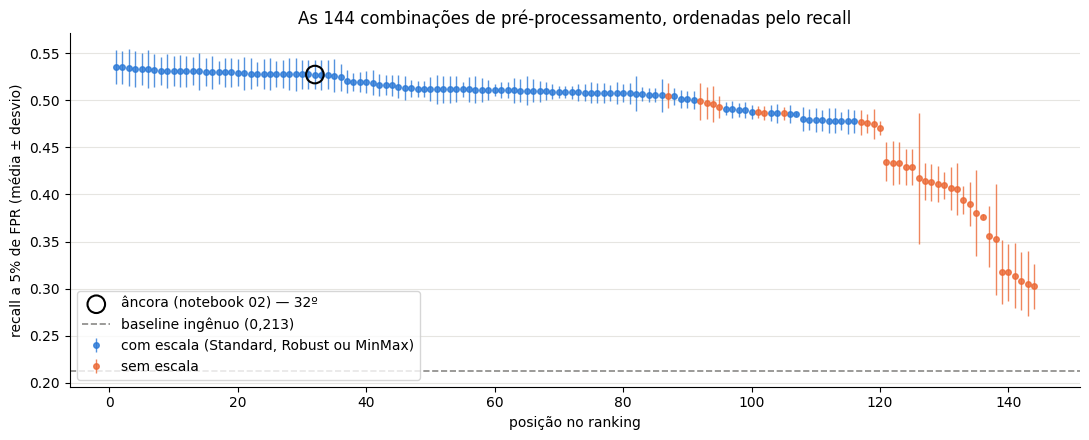

Âncora: 32º de 144 | 20 melhores entre 0.529 e 0.535


,ausentes,encoding,escala,balanceamento,selecao,recall@5%FPR média,recall@5%FPR desvio,PR-AUC média,ROC AUC média,folds sem convergir
1,mediana + indicador,one-hot,robust,undersampling,sem velocidades,"0,5351","0,0185","0,1508","0,8963",0
2,mediana + indicador,one-hot,standard,undersampling,sem velocidades,"0,5347","0,0178","0,1507","0,8963",0
3,mediana + indicador,one-hot,standard,undersampling,nenhuma,"0,5345","0,0199","0,1503","0,8964",0
4,mediana + indicador,one-hot,minmax,undersampling,nenhuma,"0,5330","0,0192","0,1500","0,8964",0
5,mediana + indicador,one-hot,minmax,undersampling,sem velocidades,"0,5328","0,0172","0,1504","0,8964",0
6,mediana + indicador,one-hot,robust,undersampling,nenhuma,"0,5326","0,0202","0,1504","0,8964",0
7,mediana + indicador,one-hot,robust,class_weight,sem velocidades,"0,5316","0,0179","0,1480","0,8959",0
8,mediana + indicador,one-hot,standard,nenhum,sem velocidades,"0,5311","0,0145","0,1510","0,8959",0
9,mediana + indicador,one-hot,minmax,class_weight,sem velocidades,"0,5311","0,0182","0,1482","0,8959",0
10,mediana + indicador,one-hot,minmax,class_weight,nenhuma,"0,5309","0,0164","0,1483","0,8961",0


In [8]:
import matplotlib.pyplot as plt

FIG_DIR = RAIZ / "reports" / "figures"
R = "recall@5%FPR"
ANCORA = CONFIGS[0]

grade = pd.read_csv(ARQ_GRADE).sort_values(f"{R} média", ascending=False).reset_index(drop=True)
grade.index += 1  # o índice passa a ser a posição no ranking (1º, 2º, ...)
pos_ancora = grade.index[grade["pipeline"] == rotulo(ANCORA)][0]

fig, ax = plt.subplots(figsize=(11, 4.5))
for sem_escala, cor, nome in [(False, "#2a78d6", "com escala (Standard, Robust ou MinMax)"),
                              (True, "#eb6834", "sem escala")]:
    parte = grade[(grade["escala"] == "nenhuma") == sem_escala]
    ax.errorbar(parte.index, parte[f"{R} média"], yerr=parte[f"{R} desvio"], fmt="o", ms=4,
                color=cor, ecolor=cor, alpha=0.8, elinewidth=1, label=nome)
ax.scatter(pos_ancora, grade.loc[pos_ancora, f"{R} média"], s=160, facecolors="none",
           edgecolors="black", lw=1.5, zorder=5, label=f"âncora (notebook 02) — {pos_ancora}º")
ax.axhline(0.213, color="#8a8986", ls="--", lw=1.2, label="baseline ingênuo (0,213)")
ax.set_xlabel("posição no ranking")
ax.set_ylabel("recall a 5% de FPR (média ± desvio)")
ax.set_title("As 144 combinações de pré-processamento, ordenadas pelo recall")
ax.legend(loc="lower left")
ax.grid(axis="y", color="#e6e5e1")
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_ranking_grade.png", dpi=150, bbox_inches="tight")
plt.show()

colunas = list(OPCOES) + [f"{R} média", f"{R} desvio", "PR-AUC média", "ROC AUC média", "folds sem convergir"]
print(f"Âncora: {pos_ancora}º de {len(grade)} | 20 melhores entre "
      f"{grade[f'{R} média'].iloc[19]:.3f} e {grade[f'{R} média'].iloc[0]:.3f}")
pd.concat([grade.head(10), grade.loc[[pos_ancora]], grade.tail(5)])[colunas] \
    .style.format(precision=4, decimal=",")

**Conclusão:**

- O ranking tem um **platô**: as 20 melhores combinações ficam entre 0,529 e 0,535 de recall, com barras de erro que se sobrepõem. A melhor (**0,535**: mediana + indicador · one-hot · Robust · undersampling · sem velocidades) supera a âncora (**0,527**, 32º lugar) por 0,008 — ganho consistente nos 3 folds (+0,010, +0,009, +0,005), mas **nulo na PR-AUC e na ROC AUC** (±0,0005).
- Ou seja: **com o básico bem feito, o pré-processamento quase não muda o resultado. O limite agora é o modelo** — motivação para comparar algoritmos no notebook 04.
- As 10 melhores usam todas **mediana + indicador** e **one-hot**; as 5 piores são todas **sem escala**, com target encoding e sem seleção (recall de ~0,30 — ainda acima do baseline ingênuo de 0,213).
- Combinações sem escala aparecem também no meio do ranking (posições ~88–120): são as que tiveram as velocidades removidas por alguma seleção — uma interação analisada na seção 5.

## 4. O efeito de cada etapa

**Pergunta:** quanto cada escolha muda o recall, **mantendo as outras etapas iguais**?

**Efeito pareado:** para cada troca (ex.: "mediana + indicador" → "mediana"), comparamos todos os pares de combinações idênticas em todas as outras etapas e calculamos a diferença de recall. A referência de cada etapa é a opção da âncora. Mostramos a média, a faixa (mínimo–máximo) e o % de pares em que a troca melhora o resultado — com todas as combinações e só com as que têm escala.

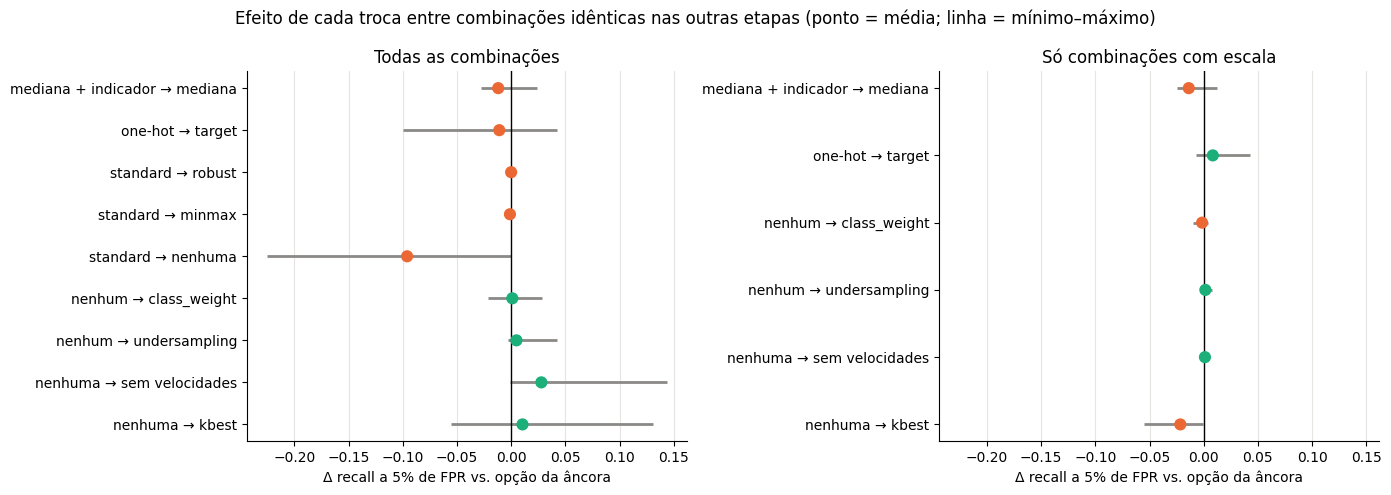

Todas as combinações:


Só combinações com escala:


In [9]:
def efeito_pareado(dados, etapa, metrica=f"{R} média"):
    """Diferença de `metrica` ao trocar a opção da âncora em `etapa`, entre combinações iguais no resto."""
    outras = [e for e in OPCOES if e != etapa]
    referencia = dados[dados[etapa] == ANCORA[etapa]].set_index(outras)[metrica]
    linhas = []
    for opcao in OPCOES[etapa][1:]:
        alternativa = dados[dados[etapa] == opcao].set_index(outras)[metrica]
        delta = (alternativa - referencia).dropna()
        if delta.empty:
            continue
        linhas.append({"etapa": etapa, "troca": f"{ANCORA[etapa]} → {opcao}", "pares": len(delta),
                       "Δ médio": delta.mean(), "Δ mínimo": delta.min(), "Δ máximo": delta.max(),
                       "% em que melhora": 100 * (delta > 0).mean()})
    return linhas


com_escala = grade[grade["escala"] != "nenhuma"]
efeitos = pd.DataFrame([l for e in OPCOES for l in efeito_pareado(grade, e)]).set_index(["etapa", "troca"])
efeitos_com_escala = pd.DataFrame(
    [l for e in OPCOES if e != "escala" for l in efeito_pareado(com_escala, e)]
).set_index(["etapa", "troca"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, tabela, titulo in [(axes[0], efeitos, "Todas as combinações"),
                           (axes[1], efeitos_com_escala, "Só combinações com escala")]:
    t = tabela.iloc[::-1]
    y = np.arange(len(t))
    ax.hlines(y, t["Δ mínimo"], t["Δ máximo"], color="#8a8986", lw=2)
    ax.scatter(t["Δ médio"], y, color=np.where(t["Δ médio"] > 0, "#1baf7a", "#eb6834"), s=60, zorder=3)
    ax.axvline(0, color="black", lw=1)
    ax.set_yticks(y, [troca for _, troca in t.index])
    ax.set_title(titulo)
    ax.set_xlabel("Δ recall a 5% de FPR vs. opção da âncora")
    ax.grid(axis="x", color="#e6e5e1")
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)
fig.suptitle("Efeito de cada troca entre combinações idênticas nas outras etapas "
             "(ponto = média; linha = mínimo–máximo)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_efeito_por_etapa.png", dpi=150, bbox_inches="tight")
plt.show()

print("Todas as combinações:")
display(efeitos.style.format(precision=4, decimal=","))
print("Só combinações com escala:")
display(efeitos_com_escala.style.format(precision=4, decimal=","))

**Conclusão:**

- **Escala é a decisão decisiva:** sem escala, o recall cai em média 0,096 (até 0,226), piora em ~97% dos pares, e o otimizador nunca converge. Os três escaladores são **equivalentes** entre si (|Δ| < 0,003).
- **O indicador de ausência ajuda:** removê-lo piora o recall em 83% dos pares com escala (Δ médio de -0,014) — confirma a hipótese da EDA de que a ausência é informativa.
- **Balanceamento não muda o resultado** (|Δ médio| ≤ 0,005): as métricas avaliam a ordenação dos scores, que pesos de classe e undersampling quase não alteram. O undersampling, porém, chega ao mesmo resultado treinando com uma fração dos dados — útil para modelos mais pesados.
- **Seleção depende da escala:** considerando todas as combinações, remover as velocidades (+0,028) e o SelectKBest (+0,010) parecem ajudar; **só com escala**, remover as velocidades é neutro (+0,001) e o SelectKBest **piora em 100% dos pares** (-0,022). O ganho aparente vinha das combinações sem escala (seção 5).
- **Encoding:** empate na prática; a vantagem do target encoding com escala (+0,008) vem quase toda das combinações com SelectKBest (seção 5).

## 5. Interações entre técnicas

**Pergunta:** alguma técnica só ajuda (ou só atrapalha) em conjunto com outra?

Para cada par de etapas, o recall médio de cada combinação de opções (média sobre as demais etapas). Sem interação, a diferença entre duas colunas seria a mesma em todas as linhas.

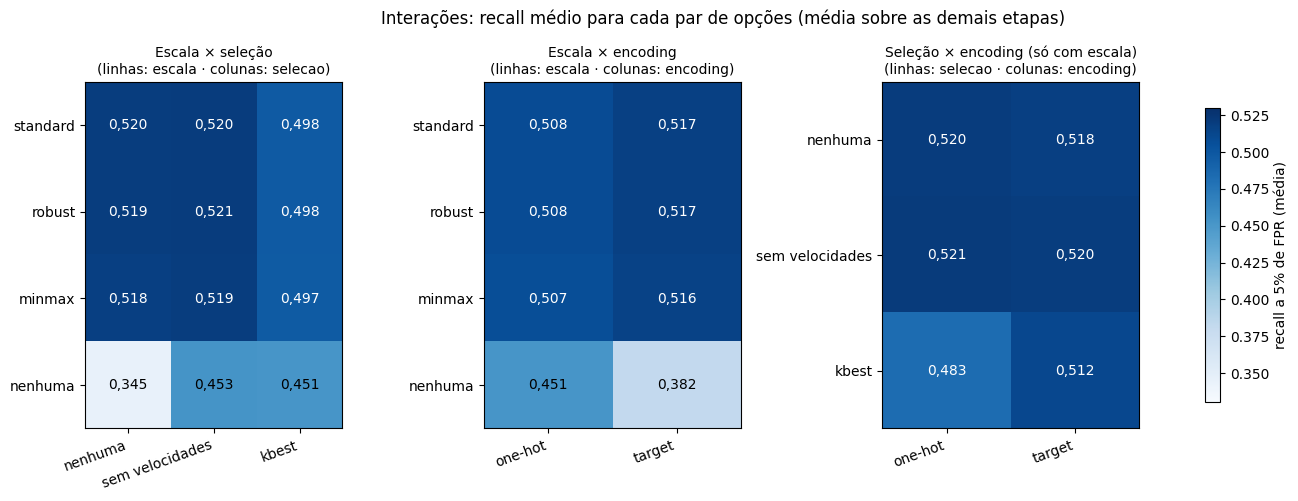

In [10]:
INTERACOES = [
    (grade, "escala", "selecao", "Escala × seleção"),
    (grade, "escala", "encoding", "Escala × encoding"),
    (com_escala, "selecao", "encoding", "Seleção × encoding (só com escala)"),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"wspace": 0.55})
for ax, (dados, linhas, colunas, titulo) in zip(axes, INTERACOES):
    tabela = dados.pivot_table(index=linhas, columns=colunas, values=f"{R} média")
    tabela = tabela.reindex(index=[o for o in OPCOES[linhas] if o in tabela.index],
                            columns=[o for o in OPCOES[colunas] if o in tabela.columns])
    im = ax.imshow(tabela, cmap="Blues", vmin=0.33, vmax=0.53, aspect="auto")
    ax.set_xticks(range(tabela.shape[1]), tabela.columns, rotation=20, ha="right")
    ax.set_yticks(range(tabela.shape[0]), tabela.index)
    for i in range(tabela.shape[0]):
        for j in range(tabela.shape[1]):
            valor = tabela.iloc[i, j]
            ax.text(j, i, f"{valor:.3f}".replace(".", ","), ha="center", va="center",
                    color="white" if valor > 0.47 else "black", fontsize=10)
    ax.set_title(f"{titulo}\n(linhas: {linhas} · colunas: {colunas})", fontsize=10)
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.85, label="recall a 5% de FPR (média)")
fig.suptitle("Interações: recall médio para cada par de opções (média sobre as demais etapas)", y=1.04)
fig.savefig(FIG_DIR / "03_interacoes.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusão:**

- **Escala × seleção:** com escala, remover as velocidades é neutro e o SelectKBest custa ~0,02. **Sem escala, as duas seleções "salvam" o modelo** (de 0,345 para ~0,45). Sem padronização, as velocidades — na casa dos milhares — dominam o otimizador; qualquer seleção que as tire da frente ajuda. A seleção não melhora o modelo: ela **compensa** a falta de escala.
- **Escala × encoding:** com escala, o target encoding fica levemente à frente (+0,009); **sem escala, ele despenca** (0,382 contra 0,451 do one-hot). O target encoding gera valores minúsculos (taxas de fraude de ~0,01), enquanto as numéricas brutas estão na casa dos milhares. Para usar uma variável em escala tão pequena, a regressão logística precisaria de um coeficiente enorme, e a regularização L2 penaliza justamente coeficientes grandes — na prática, a informação é ignorada. Com escala, todas as variáveis ficam comparáveis e o problema desaparece.
- **Seleção × encoding:** o SelectKBest prejudica muito mais o one-hot (0,483) que o target encoding (0,512). O one-hot gera ~55 colunas e o target ~35; ao manter só 20, o one-hot perde mais informação. **É daí que vem quase toda a vantagem aparente do target encoding:** sem o SelectKBest, os dois empatam (0,520 vs. 0,518).
- **Lição geral:** o efeito de uma técnica isolada pode enganar. Várias "melhorias" só aparecem para compensar outra decisão ruim.

## 6. Resumo e decisão para o notebook 04

| Decisão | Impacto no recall a 5% de FPR |
|---|---|
| Escalar as variáveis (vs. não escalar) | **+0,096** em média — a mais importante; sem escala o otimizador não converge |
| Indicador de ausência | +0,014 (melhora em 83% dos pares) — confirma a EDA |
| Tipo de escala (Standard / Robust / MinMax) | < 0,003 — equivalentes |
| Encoding (one-hot / target) | empate sem SelectKBest |
| Balanceamento (nenhum / `class_weight` / undersampling) | < 0,005 — sem efeito na ordenação |
| Remover velocidades | neutro com escala; +0,11 sem escala (compensa a falta dela) |
| SelectKBest (20 variáveis) | **-0,022** com escala (piora em 100% dos pares) |

- **Platô:** as 20 melhores combinações ficam entre 0,529 e 0,535. A âncora (notebook 02) está no 32º lugar, a 0,008 da melhor; na PR-AUC e na ROC AUC, a diferença é nula. **Com o básico bem feito, o limite passa a ser o modelo.**
- **Pré-processamento escolhido para o notebook 04:** mediana + indicador · one-hot · Standard · **undersampling (1:10)** · sem seleção — a combinação mais simples dentro do platô (3º lugar, recall de 0,5345). O undersampling não altera a qualidade e reduz o volume de treino, o que viabiliza modelos mais pesados (SVM, rede neural).
- Resultados completos em `reports/grade_03_preprocessamento.csv`.

**Próximo passo:** `04_modelos.ipynb` — comparar algoritmos (regressão logística, árvore de decisão, Naive Bayes, SVM, rede neural e LightGBM) com este pré-processamento, com busca aleatória de hiperparâmetros nos mesmos folds temporais.